In [91]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "./microcensus/dataset/wegeinland.csv"

# Grupperer transportmidler (wmittel) i hovedkategorier
MZ_MODE_MAP = {
    1: 'other',       # Flugzeug
    2: 'pt',       # bahn
    3: 'pt',      # postauto
    4: 'other',        # schiff
    5: 'pt',        # tram
    6: 'pt',        # bus
    7: 'pt',         # sonstiger oec
    8: 'other',         # reisecar
    9: 'car',         # auto
    10: 'other',     # lastwagen
    11: 'car_passenger',     # Taxi
    12: 'car',      # motorrad
    13: 'moped',      # mofa
    14: 'bike',      # velo
    15: 'walk',      # fuss
    16: 'other',      # ahrzeugähnliche Geräte
    17: 'other',      # anderes, weiss nicht, keine Antwort
    
}

In [92]:
df = pd.read_csv(file_path, encoding='latin1', low_memory=False)

In [93]:
[col for col in df.columns]

['HHNR',
 'WP',
 'AUSNR',
 'WEGNR',
 'DMOD',
 'f51100',
 'f51400',
 'f51100time',
 'f51400time',
 'pseudo',
 'W_X',
 'W_Y',
 'W_X_CH1903',
 'W_Y_CH1903',
 'W_QAL',
 'W_BFS',
 'W_PLZ',
 'W_Ort',
 'W_Str',
 'W_hnr',
 'W_SPRACHE',
 'W_REGION',
 'W_KANTON',
 'W_AGGLO2000',
 'W_AGGLO_GROESSE2000',
 'W_STRUKTUR_2000',
 'W_STRUKTUR_AGG_2000',
 'w_struktur_bfs9_2000',
 'W_AGGLO2012',
 'W_AGGLO_GROESSE2012',
 'W_staedt_char_2012',
 'W_stat_stadt_2012',
 'W_ISO_Staedte_MIV',
 'W_ISO_Staedte_OeV',
 'W_OeV_KLASSE',
 'W_DEGURBA',
 'S_X',
 'S_Y',
 'S_X_CH1903',
 'S_Y_CH1903',
 'S_QAL',
 'S_BFS',
 'S_PLZ',
 'S_Ort',
 'S_Str',
 'S_hnr',
 'S_SPRACHE',
 'S_REGION',
 'S_KANTON',
 'S_NUTS3',
 'S_LND',
 'S_AGGLO2000',
 'S_AGGLO_GROESSE2000',
 'S_STRUKTUR_2000',
 'S_STRUKTUR_AGG_2000',
 'S_struktur_bfs9_2000',
 'S_AGGLO2012',
 'S_AGGLO_GROESSE2012',
 'S_staedt_char_2012',
 'S_stat_stadt_2012',
 'S_DEGURBA',
 'Z_X',
 'Z_Y',
 'Z_X_CH1903',
 'Z_Y_CH1903',
 'Z_QAL',
 'Z_BFS',
 'Z_PLZ',
 'Z_Ort',
 'Z_Str',
 'Z_h

In [94]:
df["mode"] = df["wmittel"].map(MZ_MODE_MAP)
df["elevation"] = df["Z_Z_CH1903"] - df["S_Z_CH1903"]
df["slope"] = df["elevation"] / df["w_rdist"] * 100/1000

Total bike trips: 13769


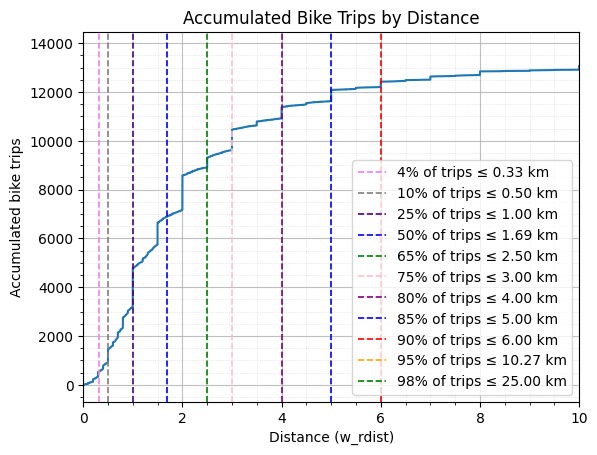

In [95]:


# Filter bike trips and sort by distance
bike_trips = df[df['mode'] == 'bike'].sort_values('w_rdist')
print(f"Total bike trips: {len(bike_trips)}")

# Accumulate bike trips by distance
bike_trips['cumulative_trips'] = np.arange(1, len(bike_trips) + 1)

# Plot accumulated bike trips vs distance
plt.plot(bike_trips['w_rdist'], bike_trips['cumulative_trips'])
plt.xlabel('Distance (w_rdist)')
plt.ylabel('Accumulated bike trips')
plt.title('Accumulated Bike Trips by Distance')
# Set maximum x-axis value (adjust as needed)
max_x = 10

plt.xlim(0, max_x)

# Fine-grained grid: major grid lines plus minor grid lines
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.8, alpha=0.8)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.5)


# Vertical lines at 85%, 90%, 95% and 98% of accumulated bike trips
for pct, color in [(4, 'violet'), (10, 'gray'), (25, 'indigo'), (50, 'blue'), (65, 'green'), (75, 'pink'), (80, 'purple'), (85, 'blue'), (90, 'red'), (95, 'orange'), (98, 'green')]:
    dist_pct = np.percentile(bike_trips['w_rdist'], pct)
    plt.axvline(dist_pct, color=color, linestyle='--', linewidth=1.2,
                label=f'{pct}% of trips ≤ {dist_pct:.2f} km')

plt.legend()


In [96]:
MIN_LENGTH = 0.33
MAX_LENGTH = 3


In [97]:
df = df[df["slope"] > 0]

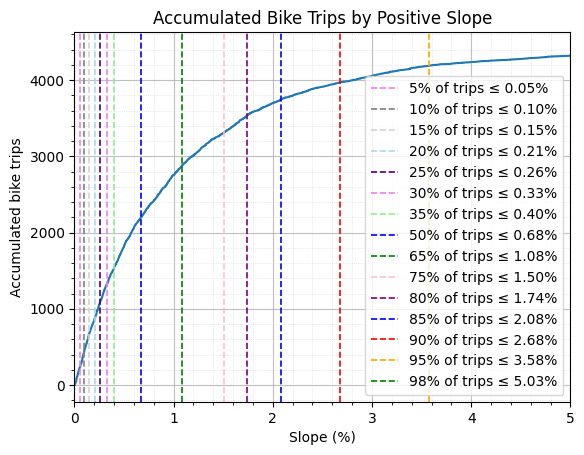

In [98]:
# Filter bike trips with positive slope and sort by slope
bike_trips_pos_slope = df[(df['mode'] == 'bike') & (df['w_rdist'] > MIN_LENGTH) & (df['w_rdist'] < MAX_LENGTH)].sort_values('slope')

# Accumulate bike trips by slope
bike_trips_pos_slope['cumulative_trips'] = np.arange(1, len(bike_trips_pos_slope) + 1)

# Plot accumulated bike trips vs slope
plt.plot(bike_trips_pos_slope['slope'], bike_trips_pos_slope['cumulative_trips'])
plt.xlabel('Slope (%)')
plt.ylabel('Accumulated bike trips')
plt.title('Accumulated Bike Trips by Positive Slope')

# Fine-grained grid: major grid lines plus minor grid lines
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.8, alpha=0.8)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.5)

# Vertical lines at percentiles of accumulated bike trips
for pct, color in [(5, 'violet'), (10, 'gray'), (15, 'lightgray'), (20, 'lightblue'),  (25, 'indigo'), (30, 'violet'), (35, 'lightgreen'), (50, 'blue'), (65, 'green'), (75, 'pink'), (80, 'purple'), (85, 'blue'), (90, 'red'), (95, 'orange'), (98, 'green')]:
    slope_val = np.percentile(bike_trips_pos_slope['slope'], pct)
    plt.axvline(slope_val, color=color, linestyle='--', linewidth=1.2,
                label=f'{pct}% of trips ≤ {slope_val:.2f}%')

plt.xlim(0, 5)
plt.legend()
plt.show()

In [ ]:
MIN_INTERVAL = [0.4, 0.68]  # 35-50%
#MAX_INTERVAL = [1.49, 2.21]  # 65-80%
MAX_INTERVAL = [1.08, 1.74]  # 65-80%

In [107]:
relevant_trips = df[(df['slope'] >= MIN_INTERVAL[0]) & (df['slope'] <= MAX_INTERVAL[1]) & (df['w_rdist'] >= MIN_LENGTH) & (df['w_rdist'] <= MAX_LENGTH)]
print(f"Number of relevant trips: {len(relevant_trips)}")
low_interval_trips = relevant_trips[(relevant_trips['slope'] >= MIN_INTERVAL[0]) & (relevant_trips['slope'] <= MIN_INTERVAL[1])]
high_interval_trips = relevant_trips[(relevant_trips['slope'] >= MAX_INTERVAL[0]) & (relevant_trips['slope'] <= MAX_INTERVAL[1])]
low_interval_mean_slope = low_interval_trips['slope'].mean()
high_interval_mean_slope = high_interval_trips['slope'].mean()

lower_slope_bike_share = len(low_interval_trips[low_interval_trips['mode'] == 'bike']) / len(low_interval_trips)
high_slope_bike_share = len(high_interval_trips[high_interval_trips['mode'] == 'bike']) / len(high_interval_trips)


print(f"""
For this we are considering only trips with distance between {MIN_LENGTH} m and {MAX_LENGTH} m, which includes 70% of biking trips.
This is divided into two groups: trips with slope between {MIN_INTERVAL[0]:.2f}% and {MIN_INTERVAL[1]:.2f}% (15% of biking trips) and trips with slope between {MIN_INTERVAL[1]:.2f}% and {MAX_INTERVAL[1]:.2f}% (15% of biking trips).
For each group, we calculate the share of trips that are biking trips.
Based on this result we can calculate the beta coefficient for slope in the utility function of biking trips, which is a measure of how much the slope affects the likelihood of choosing biking as a mode of transport.
""")
print(f"Bike share for lower slope trips: {lower_slope_bike_share:.2%}")
print(f"Bike share for higher slope trips: {high_slope_bike_share:.2%}")
beta_slope1 = (high_slope_bike_share - lower_slope_bike_share)/lower_slope_bike_share / (high_interval_mean_slope - low_interval_mean_slope)/low_interval_mean_slope
beta_slope = (high_slope_bike_share - lower_slope_bike_share)/ (high_interval_mean_slope - low_interval_mean_slope)
print(f"Beta coefficient for slope: {beta_slope:.5f}")
print(f"Beta coeffcient for slope using second model: {beta_slope1:.5f}")

Number of relevant trips: 15230

For this we are considering only trips with distance between 0.33 m and 3 m, which includes 70% of biking trips.
This is divided into two groups: trips with slope between 0.40% and 0.68% (15% of biking trips) and trips with slope between 0.68% and 1.74% (15% of biking trips).
For each group, we calculate the share of trips that are biking trips.
Based on this result we can calculate the beta coefficient for slope in the utility function of biking trips, which is a measure of how much the slope affects the likelihood of choosing biking as a mode of transport.

Bike share for lower slope trips: 15.52%
Bike share for higher slope trips: 13.32%
Beta coefficient for slope: -0.02579
Beta coeffcient for slope using second model: -0.31283


/var/folders/t_/q1zyhqk52hb1n2tywl2wjpqw0000gn/T/ipykernel_98600/3342892398.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  relevant_trips_for_plotting['slope_interval'] = pd.cut(relevant_trips_for_plotting['slope'], bins=slope_bins)


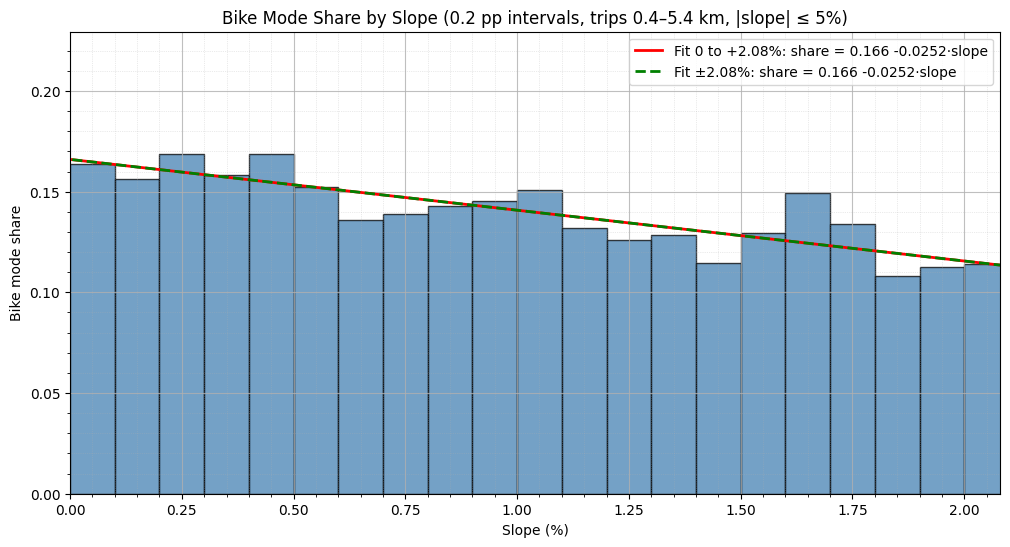

Positive-slope regression (0 to 2.08%): slope = -0.0252, intercept = 0.1660
Full-range regression (±2.08%): slope = -0.0252, intercept = 0.1660


,slope_interval,bike_share,n_trips,slope_mid
0,"(0.0, 0.1]",0.163659,3269,0.05
1,"(0.1, 0.2]",0.156506,2805,0.15
2,"(0.2, 0.3]",0.168753,2477,0.25
3,"(0.3, 0.4]",0.158452,2171,0.35
4,"(0.4, 0.5]",0.168563,1934,0.45
5,"(0.5, 0.6]",0.152135,1663,0.55
6,"(0.6, 0.7]",0.135909,1501,0.65
7,"(0.7, 0.8]",0.139156,1351,0.75
8,"(0.8, 0.9]",0.142857,1288,0.85
9,"(0.9, 1.0]",0.145498,1244,0.95


In [106]:
# Divide relevant trips into slope intervals of 0.2 percentage points
relevant_trips_for_plotting = df[(df['w_rdist'] >= MIN_LENGTH) & (df['w_rdist'] <= MAX_LENGTH)]
bin_width = .1
max_gradient = 2.08  # limit plot to ±5% slope
slope_bins = np.arange(
    np.floor(relevant_trips_for_plotting['slope'].min() / bin_width) * bin_width,
    np.ceil(relevant_trips_for_plotting['slope'].max() / bin_width) * bin_width + bin_width,
    bin_width
)
relevant_trips_for_plotting['slope_interval'] = pd.cut(relevant_trips_for_plotting['slope'], bins=slope_bins)

# Bike mode share and trip count per slope interval
bike_share_by_slope = (
    relevant_trips_for_plotting
    .assign(is_bike=relevant_trips_for_plotting['mode'] == 'bike')
    .groupby('slope_interval', observed=True)
    .agg(bike_share=('is_bike', 'mean'), n_trips=('is_bike', 'size'))
    .reset_index()
)
# .map on a categorical column keeps the categorical dtype -> convert to float
bike_share_by_slope['slope_mid'] = bike_share_by_slope['slope_interval'].map(lambda iv: iv.mid).astype(float)

# Restrict to intervals within ±5% gradient
bike_share_limited = bike_share_by_slope[bike_share_by_slope['slope_mid'].abs() <= max_gradient]

# Plot bike share per slope interval
plt.figure(figsize=(12, 6))
plt.bar(bike_share_limited['slope_mid'], bike_share_limited['bike_share'],
        width=bin_width, color='steelblue', edgecolor='black', alpha=0.75)
plt.axhline(0, color='gray', linewidth=0.8)
plt.xlim(0, max_gradient)
plt.xlabel('Slope (%)')
plt.ylabel('Bike mode share')
plt.title('Bike Mode Share by Slope (0.2 pp intervals, trips 0.4–5.4 km, |slope| ≤ 5%)')
plt.minorticks_on()
plt.grid(which='major', linestyle='-', linewidth=0.8, alpha=0.8)
plt.grid(which='minor', linestyle=':', linewidth=0.5, alpha=0.5)

# Regression 1: positive slopes only (0 to max_gradient)
pos = bike_share_limited[bike_share_limited['slope_mid'] >= 0]
slope_pos, intercept_pos = np.polyfit(pos['slope_mid'], pos['bike_share'], 1)
x_pos = np.linspace(0, max_gradient, 100)
plt.plot(x_pos, intercept_pos + slope_pos * x_pos, color='red', linewidth=2,
         label=f'Fit 0 to +{max_gradient}%: share = {intercept_pos:.3f} {slope_pos:+.4f}·slope')

# Regression 2: full range (-max_gradient to max_gradient)
slope_all, intercept_all = np.polyfit(bike_share_limited['slope_mid'], bike_share_limited['bike_share'], 1)
x_all = np.linspace(-max_gradient, max_gradient, 100)
plt.plot(x_all, intercept_all + slope_all * x_all, color='green', linewidth=2, linestyle='--',
         label=f'Fit ±{max_gradient}%: share = {intercept_all:.3f} {slope_all:+.4f}·slope')

plt.legend()
plt.show()

print(f"Positive-slope regression (0 to {max_gradient}%): slope = {slope_pos:.4f}, intercept = {intercept_pos:.4f}")
print(f"Full-range regression (±{max_gradient}%): slope = {slope_all:.4f}, intercept = {intercept_all:.4f}")

bike_share_limited